# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [61]:
print("Hello, Artificial Intelligence!")

Hello, Artificial Intelligence!


*Twoja odpowiedź:*

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [62]:
model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True

print(type(model))
print(type(version))
print(type(accuracy))
print(type(deployed))

s1 = "Model " + model + " (v" + str(version) + ") osiąga dokładność " + str(accuracy) + "."
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."
print(s1)
print(s2)

<class 'str'>
<class 'int'>
<class 'float'>
<class 'bool'>
Model NeuralNet (v2) osiąga dokładność 0.94.
Model NeuralNet (v2) osiąga dokładność 0.94.


In [63]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [64]:
acc = [0.78, 0.86, 0.92, 0.81]

n = len(acc)
mean_acc = sum(acc) / n
var_acc = sum((x - mean_acc)**2 for x in acc) / n
std_acc = var_acc ** 0.5
print(mean_acc, std_acc)



0.8425 0.05309190145398825


In [65]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [66]:
import string
translator = str.maketrans("", "", string.punctuation)
text = "AI systems learn from data. AI systems make predictions from data"

text = text.translate(translator)
text = text.lower()
words = text.split()

counts = {}
for word in words:
    if word in counts:
        counts[word] += 1
    else:
        counts[word] = 1

most_common = []
max_count = max(counts.values())
for word, count in counts.items():
    if count == max_count:
        most_common.append(word)

print(most_common)

['ai', 'systems', 'from', 'data']


In [67]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [68]:
def performance_label(score):
    try:
      experiment = score + 1
    except:
      raise TypeError("nie liczba")
    if score < 0 or score > 1:
      raise ValueError("poza zakresem")

    if score < 0.75:
      return "weak"
    elif score <= 0.90:
      return "average"
    else:
      return "strong"

scores = [0.72, 0.81, 0.93, 0.88]

mean_ok = 0
counter = 0
for score in scores:
  performance_label(score)
  if performance_label(score) != "weak":
    mean_ok += score
    counter = counter + 1


mean_ok = mean_ok / counter
print(mean_ok)



0.8733333333333334


In [69]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [70]:
results = {
    "SVM" : 0.81,
    "DecisionTree" : 0.74,
    "NeuralNet" : 0.92
}

transformer = {
    "Transformer" : 0.95
}

results.update(transformer)

mean_results = sum(results.values()) / len(results)

above_mean = []
for key, value in results.items():
  if value > mean_results:
    above_mean.append(key)

def print_ranking(results):
  for key, value in sorted(results.items(), key=lambda x: x[1], reverse=True):
    print(f"{key} - {value}")
  return max(results, key=results.get)




In [71]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

B - 0.7
A - 0.5
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [72]:
def clean_scores(raw):
  valid = []
  n_invalid = 0
  for score in raw:
    if type(score) == str or score is None or score < 0 or score > 1:
      n_invalid += 1
    else:
      valid.append(score)
      mean_valid = sum(valid) / len(valid)
  print(f"Poprawne: {len(valid)} | Błędne: {n_invalid} | Średnia (poprawnych): {mean_valid}")
  return valid, n_invalid

raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]
clean_scores(raw)

Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.8433333333333334


([0.83, 0.92, 0.78], 3)

In [73]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.8433333333333334
Poprawne: 2 | Błędne: 1 | Średnia (poprawnych): 0.5
B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [74]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [75]:
def summarize_model(info):
  print(info["name"])
  mean_score = sum(info["metrics"].values()) / len(info["metrics"])
  if mean_score >= 0.9:
    print("Model gotowy do wdrożenia")
  else:
    print("Model wymaga poprawy")
  info["mean_score"] = mean_score
  return info

model_info = summarize_model(model_info)

NeuralNet
Model wymaga poprawy


In [76]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

X
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [77]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [78]:
TP, FP, FN, TN = 0, 0, 0, 0
precision, recall, f1 = 0, 0, 0

for t, p in zip(y_true, y_pred):
  if t == 1 and p == 1:
    TP += 1
  elif t == 1 and p == 0:
    FN += 1
  elif t == 0 and p == 0:
    TN += 1
  elif t == 0 and p == 1:
    FP += 1

precision = TP/(TP+FP)
recall = TP/(TP+FN)
f1 = (2*precision*recall)/(precision + recall)





In [79]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [80]:
import numpy as np

def binary_metrics(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    actual_pos = y_true == 1
    pred_pos = y_pred == 1

    TP = int(np.sum(actual_pos & pred_pos))
    FP = int(np.sum(~actual_pos & pred_pos))
    FN = int(np.sum(actual_pos & ~pred_pos))
    TN = int(np.sum(~actual_pos & ~pred_pos))

    def safe_div(a, b):
        return float(a / b) if b != 0 else 0.0

    precision = safe_div(TP, TP + FP)
    recall = safe_div(TP, TP + FN)

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "accuracy": safe_div(TP + TN, TP + FP + FN + TN),
        "precision": precision,
        "recall": recall,
        "f1": safe_div(2 * precision * recall, precision + recall),
    }


y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

print(binary_metrics(y_true, y_pred))
print(binary_metrics(np.array(y_true), np.zeros(10, dtype=int)))



{'TP': 3, 'FP': 1, 'FN': 2, 'TN': 4, 'accuracy': 0.7, 'precision': 0.75, 'recall': 0.6, 'f1': 0.6666666666666665}
{'TP': 0, 'FP': 0, 'FN': 5, 'TN': 5, 'accuracy': 0.5, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


In [81]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [82]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)


def sklearn_metrics(y_true, y_pred):
  # Z dokumentacji sklearn C[i, j] to liczba próbek
  # których prawdziwa etykieta to klasa i, a przewidywana etykieta to klasa j
  # wiersze to prawdziwe etykiety, kolumny to przewidywane etykiety
  # Przypadek w dokumentacji był
  # TN = C[0, 0] FP = C[0, 1]
  # FN = C[1, 0] TP = C[1, 1]
  # więc ravel() spłaszcza ją wiersz po wierszu w kolejności (TN, FP, FN, TP)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0.0),
        "recall": recall_score(y_true, y_pred, zero_division=0.0),
        "f1": f1_score(y_true, y_pred, zero_division=0.0),
    }


y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

for yt, yp in [(y_true, y_pred), (np.array(y_true), np.zeros(10, dtype=int))]:
    ours = binary_metrics(yt, yp)
    ref = sklearn_metrics(yt, yp)
    for key in ours:
        assert np.isclose(ours[key], ref[key]), (key, ours[key], ref[key])
        print(f"{key:>9}: {ours[key]:.4f}  sklearn: {ref[key]:.4f}")
    print()



       TP: 3.0000  sklearn: 3.0000
       FP: 1.0000  sklearn: 1.0000
       FN: 2.0000  sklearn: 2.0000
       TN: 4.0000  sklearn: 4.0000
 accuracy: 0.7000  sklearn: 0.7000
precision: 0.7500  sklearn: 0.7500
   recall: 0.6000  sklearn: 0.6000
       f1: 0.6667  sklearn: 0.6667

       TP: 0.0000  sklearn: 0.0000
       FP: 0.0000  sklearn: 0.0000
       FN: 5.0000  sklearn: 5.0000
       TN: 5.0000  sklearn: 5.0000
 accuracy: 0.5000  sklearn: 0.5000
precision: 0.0000  sklearn: 0.0000
   recall: 0.0000  sklearn: 0.0000
       f1: 0.0000  sklearn: 0.0000



---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:* - 1) Accuracy:
  - Model zawsze-zero myli się tylko na pozytywnych, czyli w ok. 5% przypadków, więc jego accuracy około 0.95.
   - Model zaszumiony myli się w 10% przypadków niezależnie od klasy, więc jego accuracy około 0.90.
- 2) Wyższą accuracy będzie miał model zawsze-zero.
- 3) Precision modelu zaszumionego będzie bliżej 0.3.
  -  Prawdziwe pozytywne przewidziane jako 1: 0.05 · 0.9 = 0.045.
  - Negatywne odwrócone na 1: 0.95 · 0.1 = 0.095.
  - Precision = 0.045 / (0.045 + 0.095) = 0.32
  - Negatywnych jest 19 razy więcej, więc nawet 10% ich błędów zalewa prawdziwe trafienia.

Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [83]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy


### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [84]:
y_true, y_zero, y_noisy = make_data(0.05)

for name, y_pred in [("zawsze-zero", y_zero), ("zaszumiony", y_noisy)]:
    m = binary_metrics(y_true, y_pred)
    print(
        f"{name:<12} accuracy={m['accuracy']:.4f}  precision={m['precision']:.4f}  "
        f"recall={m['recall']:.4f}  f1={m['f1']:.4f}"
    )

import pandas as pd

ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows = []

for p in ps:
    y_true, y_zero, y_noisy = make_data(p)
    for name, y_pred in [("zawsze-zero", y_zero), ("zaszumiony", y_noisy)]:
        m = binary_metrics(y_true, y_pred)
        rows.append({
            "p": p,
            "model": name,
            "accuracy": m["accuracy"],
            "precision": m["precision"],
            "model": name,
            "accuracy": m["accuracy"],
            "precision": m["precision"],
            "recall": m["recall"],
            "f1": m["f1"],
        })

df = pd.DataFrame(rows)
df

zawsze-zero  accuracy=0.9492  precision=0.0000  recall=0.0000  f1=0.0000
zaszumiony   accuracy=0.9036  precision=0.3367  recall=0.9252  f1=0.4937


,p,model,accuracy,precision,recall,f1
0,0.50,zawsze-zero,0.4985,0.000000,0.000000,0.000000
1,0.50,zaszumiony,0.9036,0.902284,0.905882,0.904080
2,0.30,zawsze-zero,0.6957,0.000000,0.000000,0.000000
3,0.30,zaszumiony,0.9036,0.802268,0.906671,0.851280
4,0.10,zawsze-zero,0.9016,0.000000,0.000000,0.000000
5,0.10,zaszumiony,0.9036,0.505663,0.907520,0.649455
6,0.05,zawsze-zero,0.9492,0.000000,0.000000,0.000000
7,0.05,zaszumiony,0.9036,0.336676,0.925197,0.493697
8,0.01,zawsze-zero,0.9899,0.000000,0.000000,0.000000
9,0.01,zaszumiony,0.9036,0.090995,0.950495,0.166090


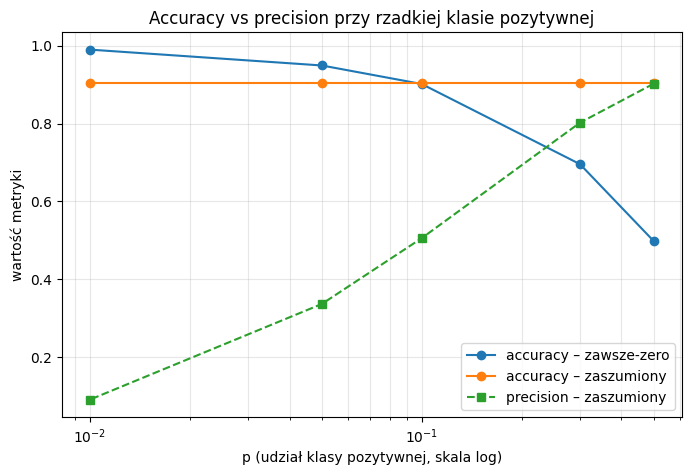

In [85]:
import matplotlib.pyplot as plt

zero = df[df["model"] == "zawsze-zero"]
noisy = df[df["model"] == "zaszumiony"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(zero["p"], zero["accuracy"], marker="o", label="accuracy – zawsze-zero")
ax.plot(noisy["p"], noisy["accuracy"], marker="o", label="accuracy – zaszumiony")
ax.plot(noisy["p"], noisy["precision"], marker="s", linestyle="--", label="precision – zaszumiony")

ax.set_xscale("log")
ax.set_xlabel("p (udział klasy pozytywnej, skala log)")
ax.set_ylabel("wartość metryki")
ax.set_title("Accuracy vs precision przy rzadkiej klasie pozytywnej")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.show()

In [86]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

*Twoja odpowiedź:*
- 1.
    Tak, dla p=0.05 model zawsze-zero ma accuracy 0.949, a zaszumiony 0.904, więc wyższa accuracy przypadła modelowi bezużytecznemu. Precision modelu zaszumionego wyniosła 0.337, czyli bliżej 0.3. Zaskakuje, jak szybko precision spada: z 0.902 przy p=0.5 do 0.091 przy p=0.01, choć accuracy tego modelu przez cały czas wynosi 0.904.
- 2.
Wyższą accuracy ma model zawsze-zero (0.990 wobec 0.904). Użyteczny jest jednak tylko zaszumiony: wykrywa 95% przypadków pozytywnych (recall 0.950), podczas gdy zawsze-zero nie wykrywa żadnego (recall 0.0, f1 0.0). Accuracy tego nie pokazuje, bo przy 99% negatywnych sama odpowiedź „0” daje prawie idealny wynik.
- 3.
    10% błędów dotyczy wszystkich przykładów, a gdy p maleje, prawie wszystkie z nich to negatywne. Przy p=0.01 na jedno prawdziwe trafienie przypada ok. 11 fałszywych, stąd precision = 0.09.
- 4.
   Jako główną metrykę zaraportowałbym recall (czułość), a obok niej precision albo F1, ale nigdy samą accuracy.


---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

1
Wynik doskonały
['SVM', 'NeuralNet', 'Transformer']


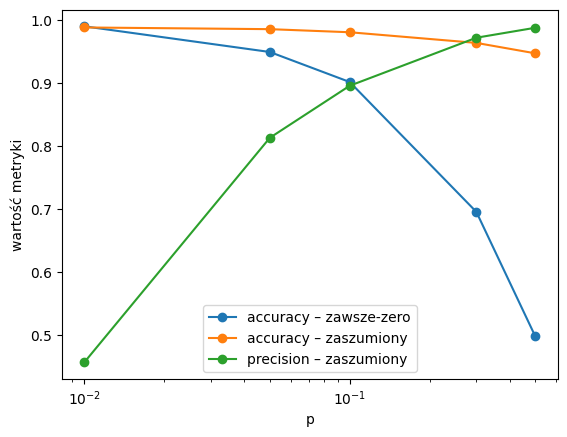

In [87]:
# E1
scores = [0.82, 0.67, 0.91, 0.74, 0.88]

with open("scores.txt", "w") as f:
    for s in scores:
        f.write(f"{s}\n")

with open("scores.txt") as f:
    loaded = [float(line) for line in f]

with open("report.txt", "w", encoding="utf-8") as f:
    f.write(f"Wczytano {len(loaded)} wyników, średnia: {sum(loaded) / len(loaded):.3f}")

# E2
try:
    s = float(input())
    if s < 0 or s > 1:
        print("Wynik poza zakresem 0–1")
    elif s < 0.7:
        print("Model wymaga poprawy")
    elif s < 0.85:
        print("Wynik akceptowalny")
    else:
        print("Wynik doskonały")
except ValueError:
    print("Podano niepoprawną wartość!")

# E3
models = ["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]
print(list(dict.fromkeys(models)))
# list(set(...)) nie gwarantuje kolejności: zbiór jest nieuporządkowany, a kolejność
# zależy od hashy (dla napisów losowanych przy każdym uruchomieniu). dict zachowuje
# kolejność wstawiania, więc dict.fromkeys zostawia pierwsze wystąpienia po kolei.


# E4
def make_data(p, n=10_000, error_pos=0.10, error_neg=0.10, seed=42):
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)
    y_zero = np.zeros(n, dtype=int)
    flip = rng.random(n) < np.where(y_true == 1, error_pos, error_neg)
    y_noisy = np.where(flip, 1 - y_true, y_true)
    return y_true, y_zero, y_noisy

acc_zero, acc_noisy, prec_noisy = [], [], []
for p in ps:
    y_true, y_zero, y_noisy = make_data(p, error_pos=0.10, error_neg=0.01)
    m_zero = binary_metrics(y_true, y_zero)
    m_noisy = binary_metrics(y_true, y_noisy)
    acc_zero.append(m_zero["accuracy"])
    acc_noisy.append(m_noisy["accuracy"])
    prec_noisy.append(m_noisy["precision"])

plt.plot(ps, acc_zero, marker="o", label="accuracy – zawsze-zero")
plt.plot(ps, acc_noisy, marker="o", label="accuracy – zaszumiony")
plt.plot(ps, prec_noisy, marker="o", label="precision – zaszumiony")
plt.xscale("log")
plt.xlabel("p")
plt.ylabel("wartość metryki")
plt.legend()
plt.show()
# Precision modelu zaszumionego jest dużo wyższa niż w D2 (p=0.05: 0.81 zamiast 0.34,
# p=0.01: 0.46 zamiast 0.09), bo fałszywe alarmy biorą się z błędów na negatywnych,
# a tych jest 10 razy mniej. Nadal jednak spada wraz z p, bo nawet 1% licznych negatywnych
# dorównuje liczbie rzadkich pozytywnych. Accuracy modelu zaszumionego rośnie z 0.947
# do 0.988, ale przy p=0.01 zawsze-zero wciąż ma minimalnie wyższą (0.990).
